# Section 5.3: reduced attitude control on $S^2$

This notebook regenerates every number that Section 5.3 of the paper states, the panels of its two figures ("Nominal gain." and "Coning gain."), and the attitude material of the supplement: the figure of interval-cell preimages on the learned spheres, the coning comparison figure, and the attitude computation details. Each step is one call of `morsegraphs.attitude_control`, and each code cell has one output.

Run it from the root of the repository. In `MODE = "replay"` it loads the fit of each gain selected by validation error and checks every result against `data/ex3_attitude_control/reference/results.json`; in `MODE = "train"` it first retrains the selected seed of each gain on the CPU with `data/ex3_attitude_control/config.json` (about three minutes per gain), then runs the same steps and reports any difference from the reference record. Results and figure panels go to `OUT`, a new folder under `outputs/notebooks/` by default.

What is proved and what is observed: the closed loop, its invariant set $\{\eta=0\}$, the coning orbit and the Conley indices of the axis dynamics in $S^2$ are proved in the paper. Everything computed from a learned map is observed: the image hulls are sampled, not validated enclosures, the residual is a sample maximum, and the agreement of learned and reference Morse graphs holds for the selected fit. The sampled residual check concerns trajectories on $\{\eta=0\}$ only, and nothing is claimed for the full state of the plant.

In [1]:
MODE = "replay"  # "replay" or "train"
OUT = None       # None, or a new folder for the results and figures
{"MODE": MODE, "OUT": OUT}

{'MODE': 'replay', 'OUT': None}

The networks run in float32 on the CPU, as when they were fitted; CMGDB, the reference maps and the tolerances use binary64. The device is chosen before JAX starts.

In [2]:
from morsegraphs import device
device.configure("float32")

{'device': 'cpu',
 'precision': 'float32',
 'remarks': ["Apple GPU unavailable for EMLP: jax-metal lacks float64 and eigh, and EMLP's PyTorch layers keep their projections on the CPU"]}

In [3]:
from morsegraphs import attitude_control as ac
run = ac.Notebook(MODE, OUT)
run

setting,value
mode,replay
data,data/ex3_attitude_control
output folder,outputs/notebooks/ex3_attitude_control-replay-20261114-011141
selected fits,"nominal-seed0, coning-seed0 (lowest validation objective, chosen before any CMGDB computation)"
networks,"JAX 0.4.38 on cpu, float32"
CMGDB,"1.5.3+fork.7, binary64, coefficients in F_5"


## The closed loop

The state $(p,v,R,\Omega)$ of the rigid body has thrust axis $q=Re_3\in S^2$ with height $z=q\cdot e_3$. For the gain $a$, $V_a(q)=a(z)(e_3-zq)+\omega e_3\times q$ with $\omega=\pi/\log 2$, $w=R\Omega$, $w_d(q)=q\times V_a(q)$ and $\eta=w-w_d(q)$. With thrust $\mu g$ and moment $M=\Omega\times J\Omega+JR^\top(Dw_d(q)[w\times q]-2\eta)$ the closed loop satisfies $\dot q=V_a(q)+\eta\times q$ and $\dot\eta=-2\eta$, and it is equivariant under rotations about $e_3$. The nominal gain is $a=1$ and the coning gain is $a(z)=1/4-z$, whose latitude $C=\{z=1/4\}$ is a periodic orbit of period $2\log 2$ with transverse Floquet multipliers $\exp(-15\log 2/8)$ and $1/16$ three times in $(q,\eta)$. These identities are proved; the table checks them in floating point on sampled states, together with the integrator used for the data.

In [4]:
run.system()

check,nominal,coning,bound or exact value
"max |η' + 2η|, closed-loop identity",2.44249e-14,1.68754e-14,< 1e-11
max |q' − V_a(q) − η × q|,4.44089e-15,4.44089e-15,< 1e-11
"equivariance of q, η, q' and M, max error",4.21885e-15,4.55191e-15,< 1e-11
"RK4 with steps 0.001 and 0.002, max difference over 1 s",4.39719e-10,3.69877e-10,< 2e-7
"observed axis against the flow of V_a on η = 0, max error over 1 s",8.29464e-11,8.90189e-11,< 2e-7
"|η(t) − exp(−2t) η(0)| for |η(0)| ≤ 6 over 20 s, max",9.96767e-10,7.32324e-10,< 2e-7
period of the coning orbit C,,1.38629,2 log 2 = 1.38629
"Floquet multipliers of C in (q, η)",,"0.0625, 0.0625, 0.0625, 0.272627, 1","1, exp(−15 log 2/8) = 0.272627, 1/16 three times"


## The reference quotient map

Let $X=S^2$ be the sphere of thrust axes and $F$ the time-one map of $V_a$. The height identifies $X/G$ with $[-1,1]$, and the quotient map is the time-one map $h_1$ of $\dot z=a(z)(1-z^2)$. Its fixed heights are the poles for the nominal gain, and the poles and $z=1/4$ for the coning gain; the table gives $h_1'$ there, exactly and by a difference quotient of the integrated flow.

In [5]:
run.reference_map()

gain,fixed set,height z*,h₁(z*),h₁'(z*) = exp(g'(z*)),difference quotient,
nominal,−e₃,-1,-1,7.38906,7.38906,repelling
nominal,e₃,1,1,0.135335,0.135335,attracting
coning,−e₃,-1,-1,12.1825,12.1825,repelling
coning,C,0.25,0.25,0.391606,0.391606,attracting
coning,e₃,1,1,4.48169,4.48169,repelling


## The reference Morse graph

On the grid of $2^7$ cells of $[-1,1]$, the outer approximation of $h_1$ is built from sampled image hulls (257 points per cell, padded by $2\cdot10^{-6}$ and cut at the poles), and CMGDB computes its Morse sets, their order and their Conley indices over $\mathbb F_5$. An index is written as CMGDB's shift class in degrees $0,1$: `x-1` is $\mathbb F$ with the identity map and `0` is zero.

In [6]:
run.reference_graphs()

gain,Morse set,cells,"cells cover, in z",Conley index (CMGDB),edges to
nominal,−e₃,1,"[-1, -0.984375]","(0, 0)",e₃
nominal,e₃,1,"[0.984375, 1]","(x-1, 0)",
coning,−e₃,1,"[-1, -0.984375]","(0, 0)",C
coning,C,2,"[0.234375, 0.265625]","(x-1, 0)",
coning,e₃,1,"[0.984375, 1]","(0, 0)",C


## The data

For each gain, complete trajectories of the plant start on $\{\eta=0\}$ with independent translation and heading, a quarter of them within $10^{-7}$ to $10^{-2}$ of a pole, and are observed every $0.1$ time units in 18 coordinates ($p$, $v$, the columns of $R$, $\Omega$). The plant is integrated by fourth-order Runge-Kutta with step $0.002$ and quaternion normalization. The splits are independent sets of trajectories; the files are checked against `metadata.json`.

In [7]:
run.data_files()

gain,split,trajectories,observations each,generator seed,file SHA-256 (first 16),checksum matches
nominal,train,8192,33,2026111311,0605d9b527cf9e0e,yes
nominal,validation,2048,33,2026111312,5ffea67d149ac624,yes
nominal,test,4096,33,2026111323,5d72f2ebe100334a,yes
coning,train,8192,33,2026111311,4ece231f0ee49168,yes
coning,validation,2048,33,2026111312,816e5300fb27b72d,yes
coning,test,4096,33,2026111323,80202008e63764f7,yes


## The fits and the selection by validation

The learned model has an equivariant encoder $E$ into a latent sphere $Z$, an axis decoder, an equivariant time-$0.1$ map $f$ of $Z$ that fixes the poles, an increasing homeomorphism $\psi$ of $[-1,1]$ and an orbit decoder. Five seeds were trained for each gain, and the seed with the lowest validation objective was selected before any CMGDB computation. All seeds are kept: coning seed 4 did not converge (validation objective 0.87, five orders of magnitude above the others) and stays in the table.

In [8]:
run.seeds()

gain,fit,rank,validation objective,test objective,one-second axis RMS (test),best step,
nominal,nominal-seed0,1,2.02913e-06,1.98303e-06,0.00100549,6000,selected
nominal,nominal-seed4,2,3.23482e-06,3.28029e-06,0.00106404,6000,
nominal,nominal-seed2,3,3.80302e-06,3.64327e-06,0.00124772,6000,
nominal,nominal-seed1,4,3.95735e-06,3.91036e-06,0.00143109,6000,
nominal,nominal-seed3,5,5.26517e-06,5.29802e-06,0.00133432,6000,
coning,coning-seed0,1,7.18928e-06,6.96636e-06,0.00183077,6000,selected
coning,coning-seed3,2,8.35951e-06,8.20601e-06,0.00151426,6000,
coning,coning-seed2,3,9.32044e-06,9.16698e-06,0.00173309,6000,
coning,coning-seed1,4,9.82513e-06,9.67018e-06,0.00206042,6000,
coning,coning-seed4,5,0.867251,0.868003,0.254183,6000,


In replay the selected fits are loaded; in train mode their seeds are trained again with the same settings, and the new weights are compared with the stored ones.

In [9]:
run.fits()

gain,fit,folder,weights SHA-256 (first 16),check
nominal,nominal-seed0,data/ex3_attitude_control/models/nominal-seed0,796adf953f3c85e7,file SHA-256 equals config.json: yes
coning,coning-seed0,data/ex3_attitude_control/models/coning-seed0,bd7f09f667f55578,file SHA-256 equals config.json: yes


## Held-out errors

Section 5.3 quotes the one-second predictions of the axis on held-out trajectories that start on $\{\eta=0\}$: componentwise root-mean-square error below $0.002$. The table recomputes it on the test trajectories, with the objective and the sampled structural checks of the fit.

In [10]:
run.errors()

quantity,nominal,coning,Section 5.3
"one-second axis RMS, componentwise (test trajectories)",0.00100549,0.00183077,below 0.002
validation objective,2.02913e-06,7.18928e-06,
test objective,1.98303e-06,6.96636e-06,
"axis prediction RMS at 1, 4 and 10 steps (test windows)",0.000498419,0.00103315,
"latent closure RMS at 1, 4 and 10 steps (test windows)",0.000643256,0.00127476,
fixed heights of fbar between the poles,,0.247074,
"sampled equivariance error of E and f, max",1.40404e-07,1.7894e-07,
"image hulls against 4,097 samples per cell, largest excess",0,0,≤ 0


## The learned Morse graphs, raw and merged

The encoder into the box is $\psi\circ\pi_Z\circ E$, and CMGDB analyzes the tenth iterate of $\psi\circ\overline f\circ\psi^{-1}$ (one time unit) on $2^7$ cells of $[-1,1]$, in the coordinate $u=\psi(z)$. For the coning gain both poles repel and one latitude attracts, so the example prescribes that the Morse sets strictly between the poles form one group: they are merged with all cells on directed paths between them, after checking that the group is order convex, that no edge leaves it and that its members other than the minimal one have trivial index, and CMGDB recomputes the Conley index on the merged index pair. The raw graph is kept.

In [11]:
run.learned_graphs()

gain,graph,Morse set,cells,"cells cover, in u",Conley index (CMGDB),edges to,Morse sets of the raw graph
nominal,raw,−e₃,1,"[-1, -0.984375]","(0, 0)",e₃,
nominal,raw,e₃,1,"[0.984375, 1]","(x-1, 0)",,
nominal,merged,−e₃,1,"[-1, -0.984375]","(0, 0)",e₃,−e₃
nominal,merged,e₃,1,"[0.984375, 1]","(x-1, 0)",,e₃
coning,raw,−e₃,1,"[-1, -0.984375]","(0, 0)",C,
coning,raw,C,1,"[0.234375, 0.25]","(x-1, 0)",,
coning,raw,A,1,"[0.25, 0.265625]","(0, 0)",C,
coning,raw,e₃,1,"[0.984375, 1]","(0, 0)",A,
coning,merged,−e₃,1,"[-1, -0.984375]","(0, 0)",C,−e₃
coning,merged,C,2,"[0.234375, 0.265625]","(x-1, 0)",,"C, A"


## Comparison with the reference

Learned nodes take the reference names only where the graphs agree. The reference is computed in $z$ and in the coordinate $\psi$ of the fit, raw and merged by the same rule. In $\psi$ both the reference and the learned coning map have a fourth Morse set, on opposite sides of $C$; after the merge the graphs coincide, cells included.

In [12]:
run.comparison()

gain,graph,Morse sets and indices,order,Morse sets between the poles,agrees with the learned graph of its kind
nominal,reference in z,"−e₃ (0, 0), e₃ (x-1, 0)",−e₃ → e₃,,order yes; indices yes
nominal,"reference in ψ, raw","−e₃ (0, 0), e₃ (x-1, 0)",−e₃ → e₃,,order yes; indices yes; cells yes
nominal,"reference in ψ, merged","−e₃ (0, 0), e₃ (x-1, 0)",−e₃ → e₃,,order yes; indices yes; cells yes
nominal,"learned, raw","−e₃ (0, 0), e₃ (x-1, 0)",−e₃ → e₃,,
nominal,"learned, merged","−e₃ (0, 0), e₃ (x-1, 0)",−e₃ → e₃,,
coning,reference in z,"−e₃ (0, 0), C (x-1, 0), e₃ (0, 0)","−e₃ → C, e₃ → C","C [0.234375, 0.265625]",order yes; indices yes
coning,"reference in ψ, raw","−e₃ (0, 0), A (0, 0), C (x-1, 0), e₃ (0, 0)","A → C, −e₃ → A, e₃ → C","C [0.25, 0.265625], A [0.234375, 0.25]",order no; indices yes; cells no
coning,"reference in ψ, merged","−e₃ (0, 0), C (x-1, 0), e₃ (0, 0)","−e₃ → C, e₃ → C","C [0.234375, 0.265625]",order yes; indices yes; cells yes
coning,"learned, raw","−e₃ (0, 0), C (x-1, 0), A (0, 0), e₃ (0, 0)","−e₃ → C, A → C, e₃ → A","C [0.234375, 0.25], A [0.25, 0.265625]",
coning,"learned, merged","−e₃ (0, 0), C (x-1, 0), e₃ (0, 0)","−e₃ → C, e₃ → C","C [0.234375, 0.265625]",


## Attracting regions, tolerances and residuals

For a minimal Morse set $\mathcal M$, $\mathcal A$ is the set of cells from which no path of the outer approximation leaves the box or reaches a Morse set outside $\mathcal M$, and $N=|\mathcal A|$. The tolerance of $N$ is the distance from the image hulls of the cells of $\mathcal A$ to the complement of $N$, and the residual modulo $G$ is $d(\overline f^{10}(\pi_Z E(x)),\pi_Z E(F(x)))$, maximized over the samples with $E(x)$ in $N$, in the chordal metric of $Z$ after undoing $\psi$. Section 5.3 reports the coning tolerance at the merged region, the region of the minimal Morse set of the merged graph. The definition of $\mathcal A$ in Section 5 is stated for a minimal Morse set, so the table also gives the region of the minimal Morse set $C$ of the raw coning graph, which excludes the cells that reach the fourth Morse set.

In [13]:
run.regions()

gain,minimal Morse set (Morse sets of the raw graph),graph,cells of 𝒜,N in u,samples in E⁻¹(N),tolerance,max residual,residual < tolerance
nominal,e₃ (e₃),merged,127,"[-0.984375, 1]",87450,0.294831,0.014871,yes
coning,"C (C, A)",merged,126,"[-0.984375, 0.984375]",76823,0.172168,0.0148922,yes
coning,C (C),raw,79,"[-0.984375, 0.25]",48090,0.00180907,0.0148922,no


## Indices in $X$

Theorem thm:sphere-reconstruction of the appendix, with $m=1$ and $\delta=\mathrm{id}$ (reduced attitude control instance), expresses the index of the lifted pair in $S^2$ through the quotient index on $(N/G,L/G)$ and the index relative to $K/G$, where $P/G=\{-1,1\}$. `morsegraphs.homology` evaluates it on the outer approximation of each graph over $\mathbb F_5$; the result is compared with the indices proved on explicit index pairs in the supplement: $H_2=\mathbb F$ at a repelling pole, $H_0=\mathbb F$ at the nominal sink $e_3$, and $H_0=H_1=\mathbb F$ at $C$, with identity index maps. For the learned maps the identification of the computed Morse sets with these invariant sets is observed.

In [14]:
run.indices()

gain,graph,Morse set,"index on [-1, 1] (CMGDB)","index on [-1, 1] (homology)",cells of N_P/G,index in S² (reconstructed),index in S² (proved),agree
nominal,reference in z,−e₃,"(0, 0)","(0, 0)",1,"(0, 0, x-1)","(0, 0, x-1)",yes
nominal,reference in z,e₃,"(x-1, 0)","(x-1, 0)",1,"(x-1, 0, 0)","(x-1, 0, 0)",yes
nominal,"reference in ψ, merged",−e₃,"(0, 0)","(0, 0)",1,"(0, 0, x-1)","(0, 0, x-1)",yes
nominal,"reference in ψ, merged",e₃,"(x-1, 0)","(x-1, 0)",1,"(x-1, 0, 0)","(x-1, 0, 0)",yes
nominal,"learned, merged",−e₃,"(0, 0)","(0, 0)",1,"(0, 0, x-1)","(0, 0, x-1)",yes
nominal,"learned, merged",e₃,"(x-1, 0)","(x-1, 0)",1,"(x-1, 0, 0)","(x-1, 0, 0)",yes
coning,reference in z,−e₃,"(0, 0)","(0, 0)",1,"(0, 0, x-1)","(0, 0, x-1)",yes
coning,reference in z,C,"(x-1, 0)","(x-1, 0)",0,"(x-1, x-1, 0)","(x-1, x-1, 0)",yes
coning,reference in z,e₃,"(0, 0)","(0, 0)",1,"(0, 0, x-1)","(0, 0, x-1)",yes
coning,"reference in ψ, merged",−e₃,"(0, 0)","(0, 0)",1,"(0, 0, x-1)","(0, 0, x-1)",yes


## Figure "Nominal gain."

(a) The merged learned Morse graph computed in $[-1,1]$, with CMGDB's indices. (b) The pullback of the attracting block to the latent sphere $Z$: preimages under $\psi\circ\pi_Z$ of the cells, with the Morse sets in their colors and the attracting region of $e_3$ in its tint. (c) The same graph with the reconstructed indices in $S^2$. Colors follow the dynamical role: attractor green, repelling poles vermilion ($-e_3$) and orange ($e_3$ for the coning gain). The panels are saved bare as PDF and SVG under `OUT/figures/attitude/nominal/`.

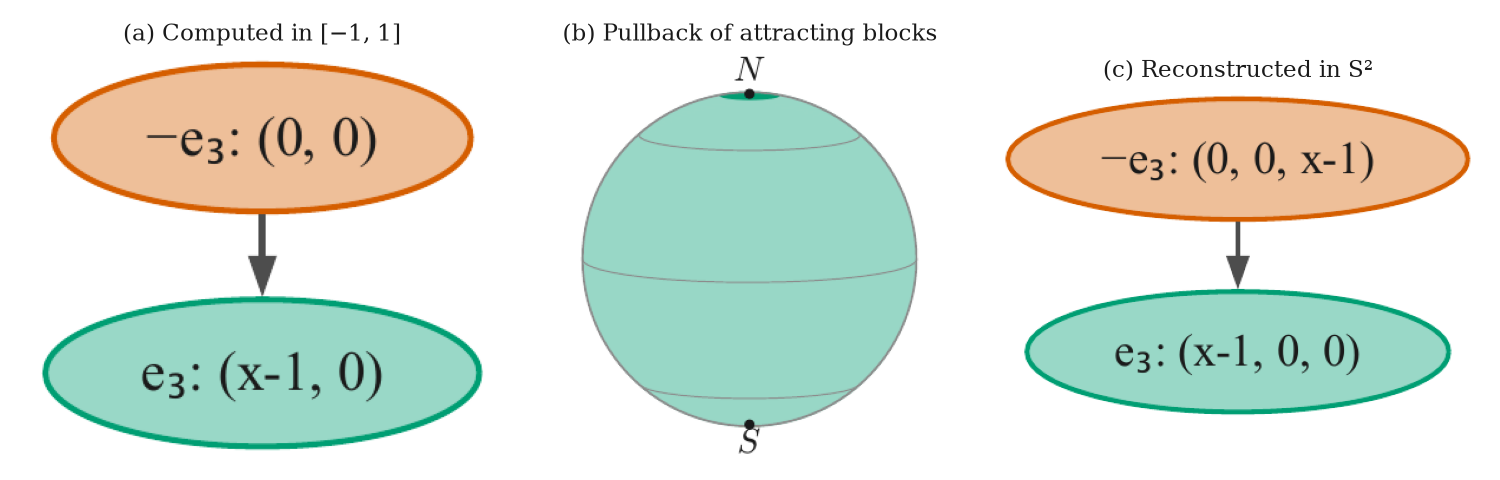

In [15]:
run.figure_nominal()

## Figure "Coning gain."

The same panels for the coning gain, from the merged graph, under `OUT/figures/attitude/coning/`. Panel (b) shows the merged region, the one at which Section 5.3 reports the tolerance.

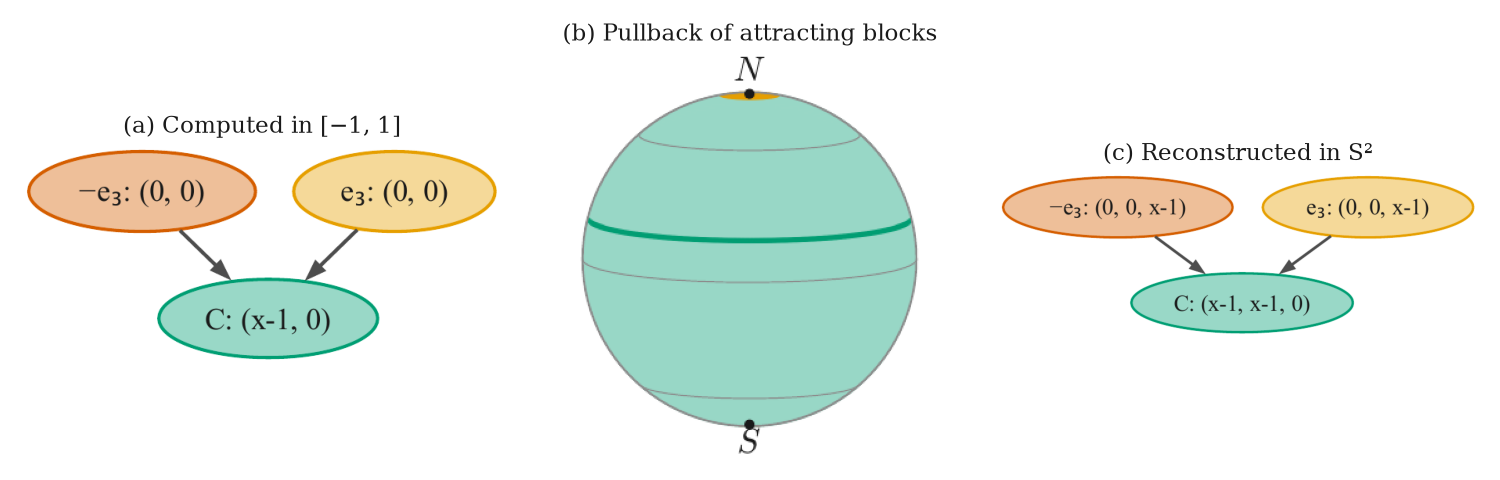

In [16]:
run.figure_coning()

The raw coning graph, with the fourth Morse set $A$ in sky blue, and the attracting region of its minimal Morse set $C$ alone. These two panels are not in the manuscript (`learned-raw-quotient` and `learned-raw-sphere`); they show the region whose tolerance the previous table gives for the raw graph.

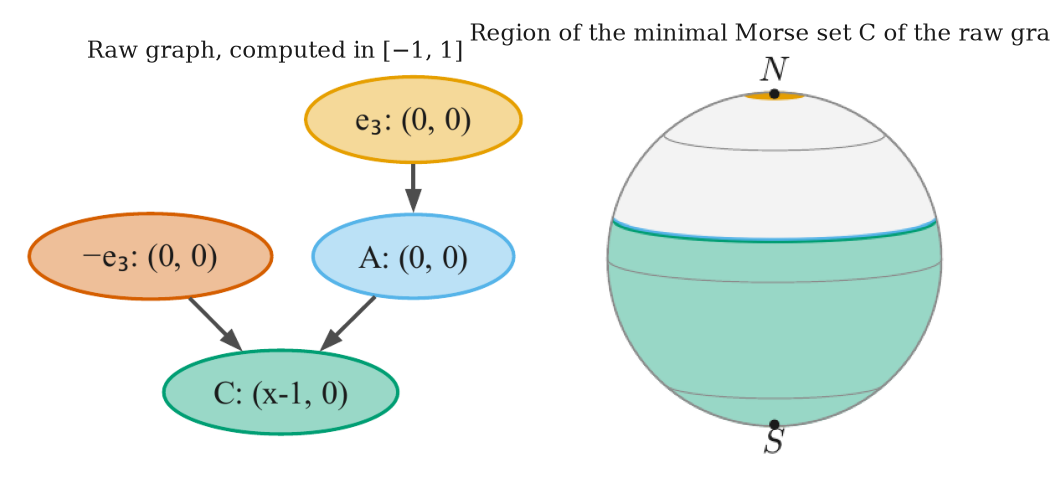

In [17]:
run.figure_coning_raw()

## Supplement: interval-cell preimages on the learned spheres

The Morse sets of the merged learned graphs on the latent sphere $Z$, preimages under $\psi\circ\pi_Z$, above their cells in the coordinate $u$ (`OUT/figures/notebook-preimages/attitude-nominal` and `attitude-coning`). They are latent-sphere preimages, not inverse images under the full-state encoder.

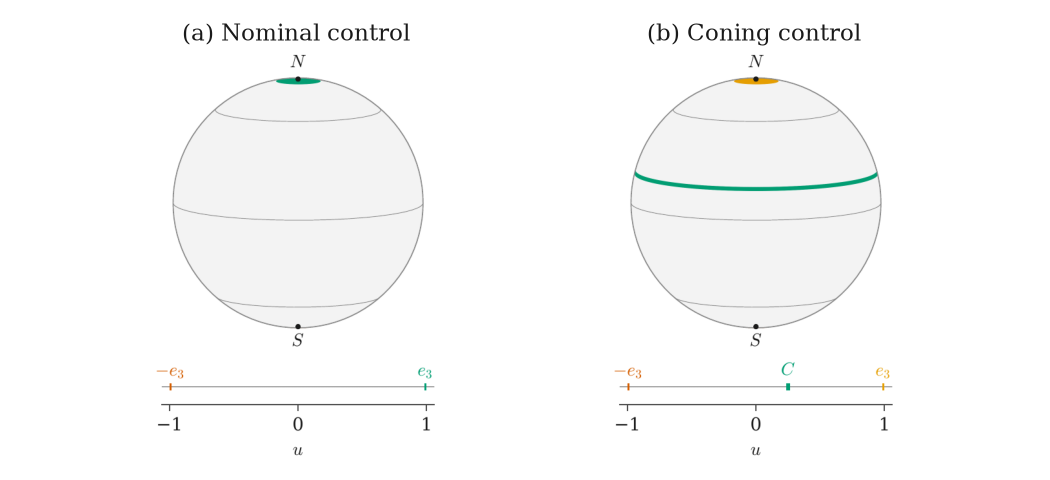

In [18]:
run.figure_appendix_spheres()

## Supplement: coning comparison

The reference in the coordinate $z$ (left) and the merged learned graph in $u$ (right). From the top: the Morse sets on the sphere ($X$ for the reference, $Z$ for the fit), their cells, the Morse graphs with CMGDB's indices, and the Morse graphs with the reconstructed indices in $S^2$. For the reference the indices in $S^2$ are proved; for the fit they refer to the latent sphere, not to the full state of the plant.

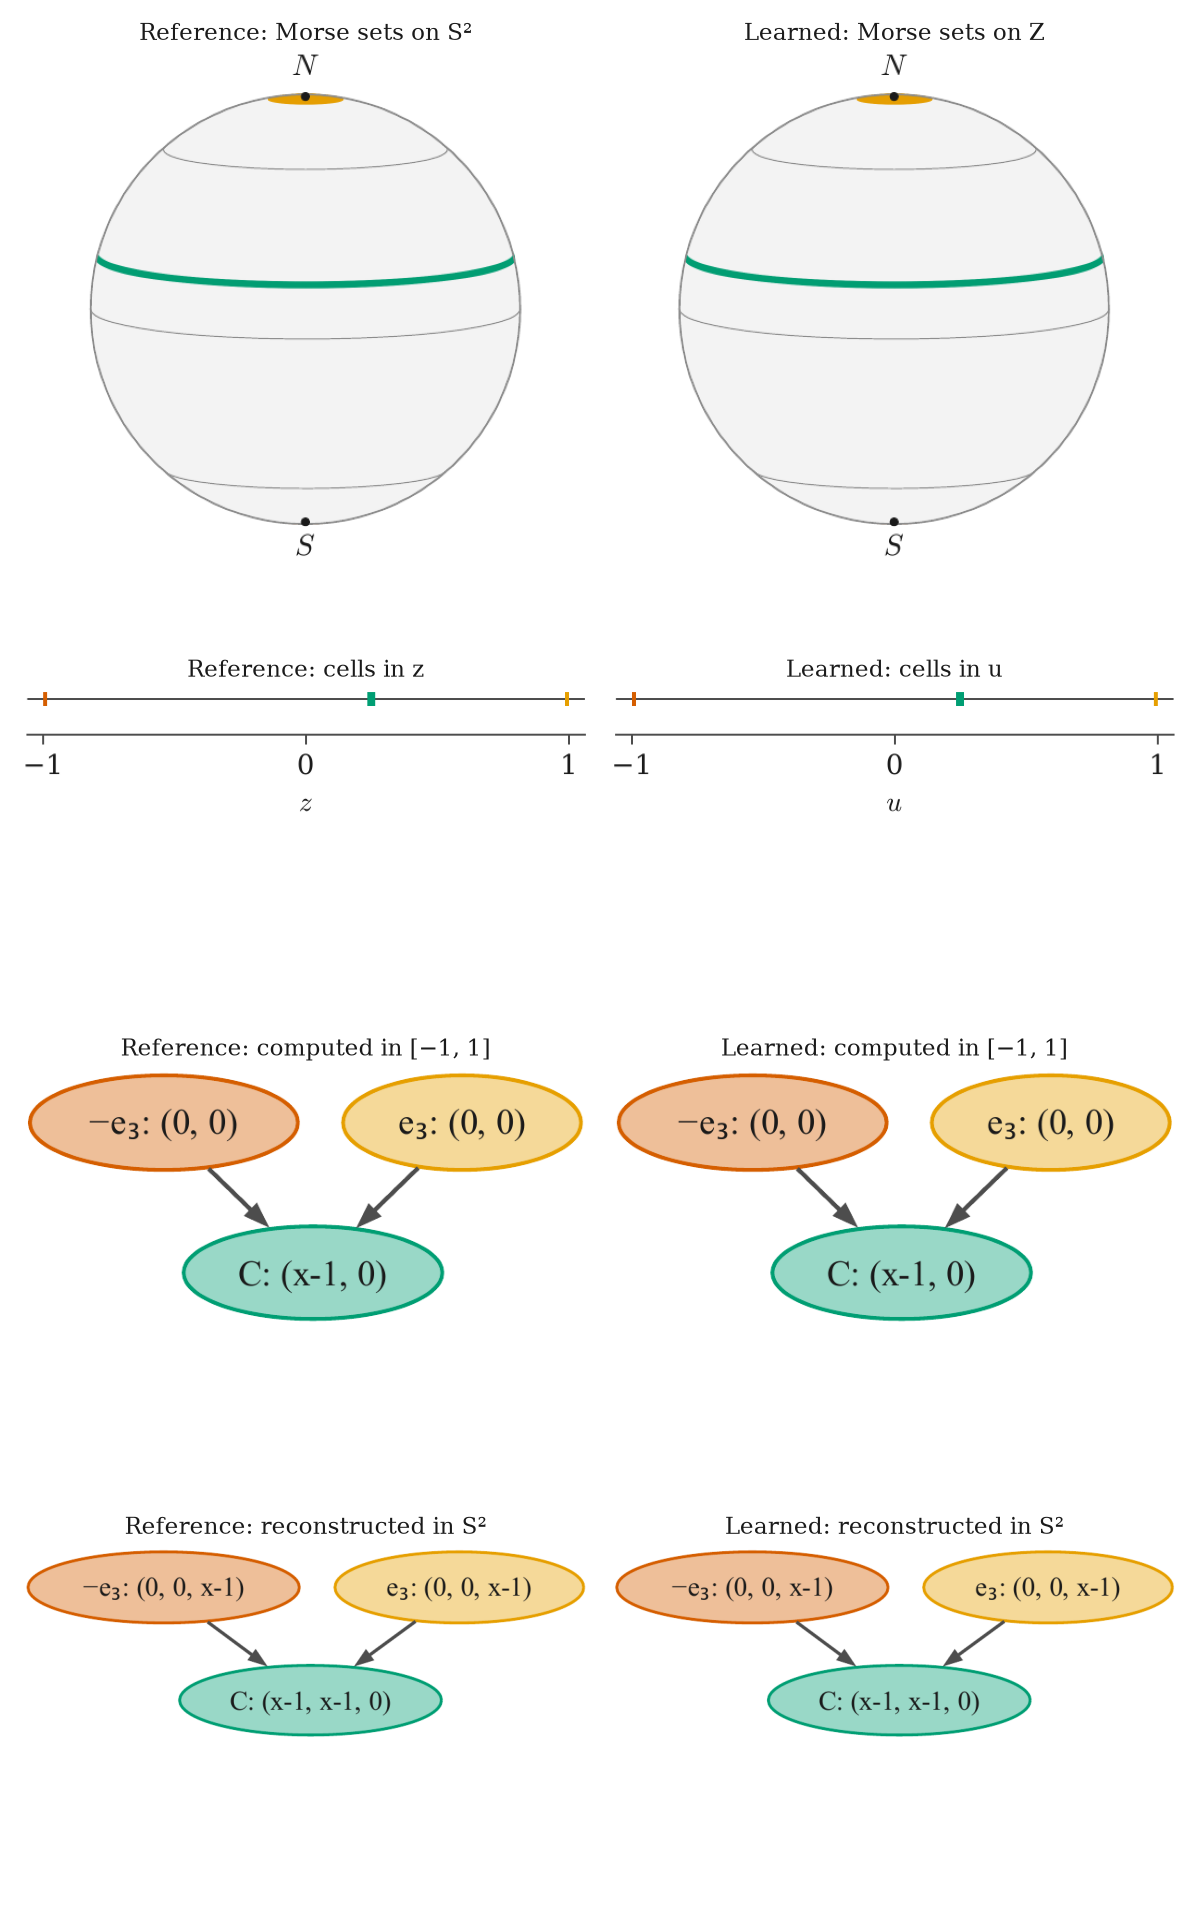

In [19]:
run.figure_appendix_comparison()

## Check against the reference record

The record of this run (graphs, regions, tolerances, residuals, indices, diagnostics and the closed-loop checks) is written to `OUT/results.json` and compared with `data/ex3_attitude_control/reference/results.json`: Morse graphs exactly, numbers to relative tolerance $10^{-9}$. In replay a difference stops the notebook; in train mode it is reported.

In [20]:
run.check()

Replay check passed: 5990 numbers and 12 Morse graphs agree with data/ex3_attitude_control/reference/results.json (graphs exactly, numbers to relative tolerance 1e-9).

## Summary

Every quantity that the manuscript states for Section 5.3 and its supplement, computed here, next to its current value in the manuscript. The comparison is informational: the text may describe an earlier fit. Times depend on the machine.

In [21]:
run.summary()

statement,where,manuscript,computed,agrees
"Coning orbit: period and transverse Floquet multipliers in (q, η)",Section 5.3,period 2 log 2; exp(−15 log 2/8) and 1/16 three times,period 1.38629; 0.272627 and 0.0625 three times; 1 along C,yes
One-second axis RMS on held-out trajectories from η = 0,Section 5.3,below 0.002,"0.00101 (nominal), 0.00183 (coning)",yes
Nominal: reference and learned Morse graphs on 2^7 cells,Section 5.3,agree; order −e₃ → e₃; matching indices,"reference −e₃ → e₃: −e₃ (0, 0), e₃ (x-1, 0); learned −e₃ → e₃: −e₃ (0, 0), e₃ (x-1, 0)",yes
Coning: reference Morse graph in z,Section 5.3,−e₃ → C ← e₃,"−e₃ → C, e₃ → C: −e₃ (0, 0), C (x-1, 0), e₃ (0, 0)",yes
Coning: a fourth Morse set in the coordinate ψ,Section 5.3,reference and learned each have one; learned: one cell next to C with zero index,"reference in ψ: A = cell [0.234375, 0.25] (0, 0); learned: A = cell [0.25, 0.265625] (0, 0)",yes
"Coning: merged Morse set, index recomputed by CMGDB on the merged pair",Section 5.3,order −e₃ → C ← e₃ of the reference,"C = [0.234375, 0.265625] from 2 Morse sets, (x-1, 0); −e₃ → C, e₃ → C",yes
Sample maxima of the residual modulo G of the tenth iterate (chordal metric),Section 5.3,0.015 for both gains,"0.014871 (nominal), 0.0148922 (coning)",yes
Estimated tolerances,Section 5.3,0.29 at e₃ (nominal) and 0.17 at the merged region (coning),"0.294831 at e₃, 0.172168 at the merged C",yes
Coning: attracting region of the minimal Morse set C of the raw graph,"Section 5, definition of 𝒜",𝒜 is defined for a minimal Morse set; Section 5.3 reports the merged region,"79 cells, tolerance 0.00180907 against residual 0.0148922 (fails)",not stated
Indices of the axis dynamics in S²,Section 5.3 and the supplement,"H₂ = F at a repelling pole, H₀ = F at the nominal sink, H₀ = H₁ = F at C","nominal: e₃ (x-1, 0, 0), −e₃ (0, 0, x-1); coning: C (x-1, x-1, 0), −e₃ (0, 0, x-1), e₃ (0, 0, x-1) (reference and learned)",yes


In [22]:
run.verification()

Wrote outputs/notebooks/ex3_attitude_control-replay-20261114-011141/verification.json: check passed, 15 statements, 16 panels as PDF and SVG.